# Datos de Colombia por API para ejercicios de Machine Learning

Descargas a escala **nacional** (y mundial cuando aplica), con volumen suficiente para entrenar modelos.
Cada bloque guarda un archivo en `data/` y sugiere una tarea de ML.

| # | Dataset | Escala | Filas aprox. | Tarea sugerida |
|---|---|---|---|---|
| 3 | Saber 11 – microdatos | estudiante | 300 mil (ajustable) | Clasificación: desempeño alto / regresión del puntaje |
| 4 | Saber 11 – agregado | municipio–periodo | ~20 mil | Regresión del puntaje promedio |
| 5 | Educación MEN | municipio–año | ~17 mil | Regresión de deserción |
| 6 | Homicidios (MinDefensa) | evento | cientos de miles | Conteos municipio–mes, clasificación del arma |
| 7 | Vehículos en accidentes de tránsito | vehículo | cientos de miles | Clasificación de la gravedad |
| 8 | Producción agrícola EVA 2007–2025 | municipio–cultivo–año | ~350 mil | Regresión del rendimiento |
| 9 | SECOP II contratos | contrato | 400 mil (ajustable) | Regresión del valor / clasificación de la modalidad |
| 10 | TRM diaria desde 1991 | día | ~12 mil | Series de tiempo |
| 11 | Banco Mundial | país–año (todo el mundo) | ~7 mil | Regresión, clustering |
| 12 | IDEAM precipitación y temperatura | estación–mes | decenas de miles | Series, interpolación espacial |
| 13 | NASA POWER | municipio–mes | ~70 mil | Series climáticas, clustering |
| 14 | Open-Meteo / ERA5 | ciudad–día | ~140 mil | Pronóstico, clasificación de día lluvioso |
| 15 | GBIF biodiversidad | registro | 40 mil | Clasificación / distribución de especies |
| 16 | Our World in Data CO₂ | país–año (todo el mundo) | ~50 mil | Regresión, series |
| 17 | Earth Engine CHIRPS (opcional) | municipio–año | ~11 mil | Regresión espacial |

Al final hay un **panel municipal nacional** y dos **modelos base** (clasificación y regresión).

In [2]:
%pip install -q requests pandas pyarrow wbgapi scikit-learn matplotlib
# Opcional para el bloque 17: %pip install -q earthengine-api

## 0. Funciones base

- `socrata()`: descarga desde datos.gov.co paginando de 50 mil en 50 mil. `max_rows` limita el total.
- `guardar()`: guarda en Parquet (rápido y liviano) y muestra tamaño y memoria.
- `cod5()`: normaliza cualquier código DANE de municipio a 5 dígitos (algunas fuentes traen 8, otras pierden el cero inicial).

Con un *app token* gratuito de datos.gov.co (perfil → Developer Settings) las descargas grandes son más estables.

In [3]:
import os, time, requests, numpy as np, pandas as pd
from pathlib import Path

DATA = Path("data"); DATA.mkdir(exist_ok=True)
BASE = "https://www.datos.gov.co/resource/{}.json"
TOKEN = os.getenv("SOCRATA_APP_TOKEN")              # os.environ["SOCRATA_APP_TOKEN"] = "tu_token"
HEADERS = {"X-App-Token": TOKEN} if TOKEN else {}

def socrata(dataset_id, select=None, where=None, group=None, order=None,
            limit=50000, max_rows=None, timeout=300, reintentos=3):
    """Descarga un dataset de datos.gov.co con paginación y reintentos."""
    params = {"$limit": limit}
    if select: params["$select"] = select
    if where:  params["$where"]  = where
    if group:  params["$group"]  = group
    params["$order"] = order or (group if group else ":id")
    frames, offset = [], 0
    while True:
        params["$offset"] = offset
        for intento in range(reintentos):
            try:
                r = requests.get(BASE.format(dataset_id), params=params, headers=HEADERS, timeout=timeout)
                r.raise_for_status()
                break
            except requests.RequestException as e:
                if intento == reintentos - 1:
                    raise
                print(f"  reintento {intento + 1}: {e}")
                time.sleep(5 * (intento + 1))
        batch = r.json()
        if not batch:
            break
        frames.append(pd.DataFrame(batch))
        offset += len(batch)
        print(f"  {dataset_id}: {offset:,} filas", end="\r")
        if len(batch) < limit or (max_rows and offset >= max_rows):
            break
        time.sleep(0.3)
    print()
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

def guardar(df, nombre):
    ruta = DATA / f"{nombre}.parquet"
    df.to_parquet(ruta, index=False)
    print(f"{nombre}: {df.shape[0]:,} filas × {df.shape[1]} columnas | "
          f"{df.memory_usage(deep=True).sum() / 1e6:.1f} MB en memoria → {ruta}")
    return df

def cod5(s):
    """Código DANE de municipio a 5 dígitos."""
    s = pd.Series(s).astype(str).str.replace(r"\.0$", "", regex=True).str.replace(r"\D", "", regex=True)
    return np.where(s.str.len() >= 7, s.str.zfill(8).str[:5], s.str.zfill(5))

def a_numero(df, cols):
    for c in cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    return df

## 1. Buscar más datasets en el catálogo de datos.gov.co

In [3]:
def buscar_datasets(texto, n=20):
    p = {"domains": "www.datos.gov.co", "search_context": "www.datos.gov.co",
         "q": texto, "limit": n, "only": "datasets"}
    res = requests.get("https://api.us.socrata.com/api/catalog/v1", params=p, timeout=60).json()["results"]
    return pd.DataFrame([{"id": x["resource"]["id"], "nombre": x["resource"]["name"],
                          "entidad": x["resource"].get("attribution"),
                          "columnas": len(x["resource"].get("columns_field_name", []))} for x in res])

buscar_datasets("accidentes de tránsito")

,id,nombre,entidad,columnas
0,ntej-qq7v,LESIONES ACCIDENTES DE TRÁNSITO,"Ministerio de Defensa Nacional - MinDefensa, B...",6
1,ha6j-pa2r,Homicidios accidente de tránsito Policía Nacional,Dirección General de la Policía Nacional - DIP...,9
2,2bk8-65js,Mortalidad por Accidentes de Tránsito General,"Dirección Territorial de Salud de Caldas, Caldas",19
3,uav5-b85g,HOMICIDIO EN ACCIDENTE DE TRÁNSITO,"Ministerio de Defensa Nacional - MinDefensa, B...",6
4,22ip-4jk2,Accidentes de Tránsito registrados en el munic...,"Alcaldía de Fusagasugá, Cundinamarca",27
5,8rme-4s7n,Guadalajara de Buga : Homicidios por Accidente...,"Alcaldía de Guadalajara de Buga, Valle del Cauca",8
6,72sg-cybi,Reporte Lesiones Personales y en Accidente de ...,Dirección General de la Policía Nacional - DIP...,9
7,g4vd-w4ip,9. Costos de la atención hospitalaria en Bucar...,"Alcaldía de Bucaramanga, Santander",33
8,xpyu-s4ma,Accidentes de tránsito reportados en los munic...,"Gobernación de Antioquia, Antioquia",21
9,6jmc-vaxk,VEHICULOS INVOLUCRADOS EN UN ACCIDENTE DE TRAN...,"Ministerio de Transporte - MinTransporte, Bogo...",9


## 2. DIVIPOLA — códigos y coordenadas de los 1.100+ municipios · `gdxc-w37w`

In [4]:
divipola = socrata("gdxc-w37w")
divipola["cod_mpio"] = cod5(divipola["cod_mpio"])
divipola["cod_dpto"] = divipola["cod_dpto"].astype(str).str.zfill(2)
for c in ["latitud", "longitud"]:
    divipola[c] = pd.to_numeric(divipola[c].astype(str).str.replace(",", "."), errors="coerce")
guardar(divipola, "divipola").head()

  gdxc-w37w: 1,122 filas
divipola: 1,122 filas × 7 columnas | 0.4 MB en memoria → data/divipola.parquet


,cod_dpto,dpto,cod_mpio,nom_mpio,tipo_municipio,longitud,latitud
0,05,ANTIOQUIA,05001,MEDELLÍN,Municipio,-75.581775,6.246631
1,05,ANTIOQUIA,05002,ABEJORRAL,Municipio,-75.428739,5.789315
2,05,ANTIOQUIA,05004,ABRIAQUÍ,Municipio,-76.064304,6.632282
3,05,ANTIOQUIA,05021,ALEJANDRÍA,Municipio,-75.141346,6.376061
4,05,ANTIOQUIA,05030,AMAGÁ,Municipio,-75.702188,6.038708


# Social

## 3. Saber 11 — microdatos por estudiante · `kgxf-xxbe`

Variables del colegio y del hogar + puntajes. Sube `max_rows` si quieres más (la tabla completa tiene millones).

  kgxf-xxbe: 300,000 filas
saber11_micro: 300,000 filas × 27 columnas | 380.3 MB en memoria → data/saber11_micro.parquet


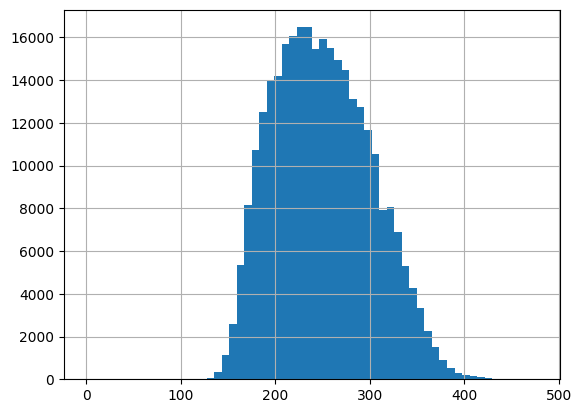

In [5]:
cols_saber = """periodo, cole_area_ubicacion, cole_bilingue, cole_calendario, cole_caracter, cole_genero,
cole_jornada, cole_naturaleza, cole_depto_ubicacion, cole_cod_mcpio_ubicacion, estu_genero,
fami_cuartoshogar, fami_educacionmadre, fami_educacionpadre, fami_estratovivienda, fami_personashogar,
fami_tieneautomovil, fami_tienecomputador, fami_tieneinternet, fami_tienelavadora,
punt_ingles, punt_matematicas, punt_sociales_ciudadanas, punt_c_naturales, punt_lectura_critica, punt_global"""

saber = socrata("kgxf-xxbe", select=cols_saber,
                where="periodo::number >= 20221 AND punt_global IS NOT NULL",
                max_rows=300_000)
saber["cod_mpio"] = cod5(saber["cole_cod_mcpio_ubicacion"])
saber = a_numero(saber, [c for c in saber.columns if c.startswith("punt_")])
guardar(saber, "saber11_micro")
saber["punt_global"].hist(bins=60);

## 4. Saber 11 — promedio por municipio y periodo (todo el histórico)

La agregación se hace en el servidor. Puede tardar 1–3 minutos.

In [ ]:
saber_mun = socrata("kgxf-xxbe",
    select=("cole_cod_mcpio_ubicacion, cole_depto_ubicacion, periodo, "
            "avg(punt_global::number) as prom_global, avg(punt_matematicas::number) as prom_mate, "
            "count(*) as estudiantes"),
    group="cole_cod_mcpio_ubicacion, cole_depto_ubicacion, periodo")
saber_mun["cod_mpio"] = cod5(saber_mun["cole_cod_mcpio_ubicacion"])
saber_mun["anio"] = saber_mun["periodo"].astype(str).str[:4].astype(int)
saber_mun = a_numero(saber_mun, ["prom_global", "prom_mate", "estudiantes"])
guardar(saber_mun, "saber11_municipio").head()

## 5. Educación básica y media — todos los municipios, todos los años (MEN) · `nudc-7mev`

In [ ]:
edu = socrata("nudc-7mev")
edu = edu.rename(columns={"a_o": "anio", "c_digo_municipio": "cod_mpio", "c_digo_departamento": "cod_dpto"})
edu["cod_mpio"] = cod5(edu["cod_mpio"])
num = [c for c in edu.columns if c not in ["cod_mpio", "municipio", "cod_dpto", "departamento", "c_digo_etc", "etc"]]
edu = a_numero(edu, num)
guardar(edu, "educacion_municipal")
edu.describe().T.head(15)

## 6. Homicidios — registro nacional por evento (MinDefensa) · `m8fd-ahd9`

In [ ]:
homi = socrata("m8fd-ahd9", max_rows=1_000_000)
homi["fecha"] = pd.to_datetime(homi["fecha_hecho"], dayfirst=True, errors="coerce")
homi["cod_mpio"] = cod5(homi["cod_muni"])
homi["cantidad"] = pd.to_numeric(homi["cantidad"], errors="coerce").fillna(1)
guardar(homi, "homicidios_eventos")

# Panel de conteos municipio–mes (para regresión de Poisson, árboles, series)
homi_mes = (homi.dropna(subset=["fecha"])
                .groupby(["cod_mpio", pd.Grouper(key="fecha", freq="MS")])["cantidad"].sum()
                .rename("homicidios").reset_index())
guardar(homi_mes, "homicidios_municipio_mes")
homi.groupby(homi["fecha"].dt.year)["cantidad"].sum().plot(kind="bar", title="Homicidios por año");

## 7. Vehículos involucrados en accidentes de tránsito (MinTransporte) · `6jmc-vaxk`

Buen dataset de **clasificación**: predecir `gravedad_accidente` con tipo, marca, modelo y edad del vehículo, lugar y fecha.

In [ ]:
acc = socrata("6jmc-vaxk", max_rows=600_000)
acc["fecha"] = pd.to_datetime(acc["fecha_accidente"], errors="coerce")
acc = a_numero(acc, ["edad_vehiculo", "modelo_vehiculo"])
guardar(acc, "accidentes_vehiculos")
acc["gravedad_accidente"].value_counts(normalize=True)

# Económico

## 8. Producción agrícola municipal EVA 2007–2025 — todo el país y todos los cultivos

MinAgricultura 2007–2018 (`2pnw-mmge`) + UPRA 2019–2025 (`uejq-wxrr`), armonizadas.

In [ ]:
eva_a = socrata("2pnw-mmge")
eva_b = socrata("uejq-wxrr")

eva_a = eva_a.rename(columns={"c_d_dep": "cod_dpto", "c_d_mun": "cod_mpio", "a_o": "anio",
    "grupo_de_cultivo": "grupo", "subgrupo_de_cultivo": "subgrupo", "rea_sembrada_ha": "area_sembrada",
    "rea_cosechada_ha": "area_cosechada", "producci_n_t": "produccion_t", "rendimiento_t_ha": "rendimiento",
    "ciclo_de_cultivo": "ciclo"})
eva_b = eva_b.rename(columns={"c_digo_dane_departamento": "cod_dpto", "c_digo_dane_municipio": "cod_mpio",
    "a_o": "anio", "grupo_cultivo": "grupo", "rea_sembrada": "area_sembrada", "rea_cosechada": "area_cosechada",
    "producci_n": "produccion_t", "ciclo_del_cultivo": "ciclo"})

cols = ["cod_dpto", "departamento", "cod_mpio", "municipio", "grupo", "subgrupo", "cultivo", "ciclo",
        "anio", "periodo", "area_sembrada", "area_cosechada", "produccion_t", "rendimiento"]
eva = pd.concat([eva_a[cols].assign(fuente="MADR"), eva_b[cols].assign(fuente="UPRA")], ignore_index=True)
eva["cod_mpio"] = cod5(eva["cod_mpio"])
eva = a_numero(eva, ["anio", "area_sembrada", "area_cosechada", "produccion_t", "rendimiento"])
for c in ["departamento", "municipio", "grupo", "subgrupo", "cultivo", "ciclo"]:
    eva[c] = eva[c].astype(str).str.upper().str.strip()
guardar(eva, "eva_agricola")
eva.groupby("anio")["produccion_t"].sum().div(1e6).plot(title="Producción agrícola total (millones de t)");

## 9. SECOP II — contratos públicos de todo el país · `jbjy-vk9h`

Solo variables útiles para modelar (sin datos de personas). Ajusta fecha y `max_rows`.

  jbjy-vk9h: 400,000 filas
secop_contratos: 400,000 filas × 20 columnas | 423.2 MB en memoria → data/secop_contratos.parquet


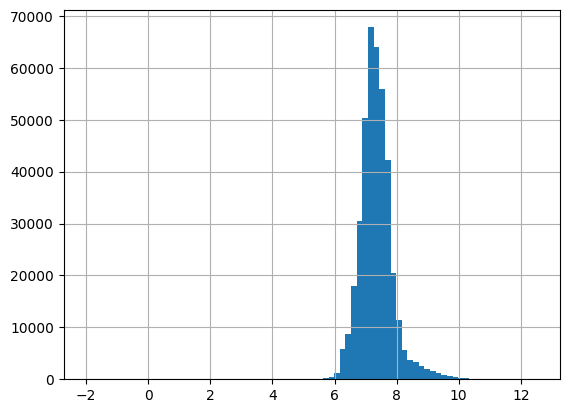

In [4]:
cols_secop = """departamento, ciudad, orden, sector, rama, entidad_centralizada, tipo_de_contrato,
modalidad_de_contratacion, codigo_de_categoria_principal, fecha_de_firma, fecha_de_inicio_del_contrato,
fecha_de_fin_del_contrato, es_pyme, origen_de_los_recursos, destino_gasto, espostconflicto,
valor_del_contrato, estado_contrato"""

secop = socrata("jbjy-vk9h", select=cols_secop,
                where="fecha_de_firma >= '2023-01-01T00:00:00' AND valor_del_contrato > 0",
                max_rows=400_000)
for c in ["fecha_de_firma", "fecha_de_inicio_del_contrato", "fecha_de_fin_del_contrato"]:
    secop[c] = pd.to_datetime(secop[c], errors="coerce")
secop["valor_del_contrato"] = pd.to_numeric(secop["valor_del_contrato"], errors="coerce")
secop["duracion_dias"] = (secop["fecha_de_fin_del_contrato"] - secop["fecha_de_inicio_del_contrato"]).dt.days
secop["log_valor"] = np.log10(secop["valor_del_contrato"])
guardar(secop, "secop_contratos")
secop["log_valor"].hist(bins=80);

## 10. TRM diaria desde 1991 (Superfinanciera) · `32sa-8pi3`

In [ ]:
trm = socrata("32sa-8pi3", order="vigenciadesde")
trm["fecha"] = pd.to_datetime(trm["vigenciadesde"])
trm["trm"] = pd.to_numeric(trm["valor"])
trm = trm[["fecha", "trm"]].sort_values("fecha")
guardar(trm, "trm_diaria")
trm.set_index("fecha")["trm"].plot(title="TRM (COP/USD)");

## 11. Banco Mundial — panel de todos los países, 1990–2023

Ejemplo de tarea: predecir la esperanza de vida a partir de los demás indicadores. Busca más con `wb.series.info(q="...")`.

In [ ]:
import wbgapi as wb

indicadores = {
    "SP.DYN.LE00.IN": "esperanza_vida",
    "NY.GDP.PCAP.KD": "pib_pc",
    "SP.POP.TOTL":    "poblacion",
    "SP.URB.TOTL.IN.ZS": "urbano_pct",
    "SP.DYN.TFRT.IN": "fecundidad",
    "SH.DYN.MORT":    "mortalidad_infantil",
    "SE.PRM.ENRR":    "matricula_primaria",
    "SL.UEM.TOTL.ZS": "desempleo",
    "EG.ELC.ACCS.ZS": "acceso_electricidad",
    "SH.H2O.BASW.ZS": "acceso_agua",
    "AG.LND.FRST.ZS": "bosque_pct",
    "NV.AGR.TOTL.ZS": "agro_pct_pib",
    "SI.POV.GINI":    "gini",
}
raw = wb.data.DataFrame(list(indicadores), "all", time=range(1990, 2024),
                        skipAggs=True, numericTimeKeys=True)
largo = raw.stack().reset_index()
largo.columns = ["economy", "series", "anio", "valor"]
wbp = (largo.pivot_table(index=["economy", "anio"], columns="series", values="valor")
          .rename(columns=indicadores).reset_index())
guardar(wbp, "banco_mundial_panel")
wbp.isna().mean().round(2).sort_values()

# Ambiental

## 12. IDEAM — precipitación y temperatura mensual de todas las estaciones

Se agrega por estación y mes en el servidor, un año a la vez (las tablas crudas son enormes). `n_obs` sirve para filtrar meses con pocos datos.

In [ ]:
def ideam_mensual(dataset_id, agregado, nombre_var, anios):
    sel = ("codigoestacion, nombreestacion, departamento, municipio, latitud, longitud, "
           f"date_trunc_ym(fechaobservacion) as mes, {agregado}(valorobservado::number) as {nombre_var}, "
           "count(*) as n_obs")
    grp = ("codigoestacion, nombreestacion, departamento, municipio, latitud, longitud, "
           "date_trunc_ym(fechaobservacion)")
    partes = []
    for a in anios:
        try:
            df = socrata(dataset_id, select=sel, group=grp,
                         where=f"fechaobservacion between '{a}-01-01T00:00:00' and '{a}-12-31T23:59:59'")
            partes.append(df)
            print(f"{a}: {len(df):,} estación-mes")
        except Exception as e:
            print(f"{a}: falló ({e}); prueba con un rango más corto")
    out = pd.concat(partes, ignore_index=True)
    out["mes"] = pd.to_datetime(out["mes"])
    return a_numero(out, [nombre_var, "n_obs", "latitud", "longitud"])

anios = range(2015, 2025)
ppt_m  = ideam_mensual("s54a-sgyg", "sum", "ppt_mm", anios)
temp_m = ideam_mensual("sbwg-7ju4", "avg", "temp_c", anios)

ideam = ppt_m.merge(temp_m[["codigoestacion", "mes", "temp_c"]], on=["codigoestacion", "mes"], how="outer")
guardar(ideam, "ideam_estacion_mes")

## 13. NASA POWER — clima mensual 1985–2024 para una muestra de municipios

Usa las coordenadas de DIVIPOLA. Con `n_municipios = 150` son unas 72 mil filas; tarda varios minutos.

In [ ]:
vars_power = "PRECTOTCORR,T2M,T2M_MAX,T2M_MIN,RH2M,WS2M,ALLSKY_SFC_SW_DWN"
n_municipios = 150
muestra = divipola.dropna(subset=["latitud", "longitud"]).sample(n_municipios, random_state=42)

partes = []
for i, fila in enumerate(muestra.itertuples(), 1):
    p = {"parameters": vars_power, "community": "AG", "latitude": fila.latitud, "longitude": fila.longitud,
         "start": 1985, "end": 2024, "format": "JSON"}
    try:
        js = requests.get("https://power.larc.nasa.gov/api/temporal/monthly/point",
                          params=p, timeout=120).json()["properties"]["parameter"]
        df = pd.DataFrame(js)
        df = df[~df.index.str.endswith("13")]                  # quita el promedio anual
        df.index = pd.to_datetime(df.index, format="%Y%m")
        df = df.replace(-999, np.nan).rename_axis("mes").reset_index()
        df["cod_mpio"], df["municipio"], df["dpto"] = fila.cod_mpio, fila.nom_mpio, fila.dpto
        df["latitud"], df["longitud"] = fila.latitud, fila.longitud
        partes.append(df)
    except Exception as e:
        print(f"{fila.nom_mpio}: {e}")
    print(f"  {i}/{n_municipios}", end="\r")
    time.sleep(1)

power = guardar(pd.concat(partes, ignore_index=True), "nasa_power_municipio_mes")

## 14. Open-Meteo Historical (ERA5) — clima diario 2000–2024 en 15 ciudades

In [ ]:
ciudades = {
    "Bogotá": (4.711, -74.072), "Medellín": (6.244, -75.581), "Cali": (3.452, -76.532),
    "Barranquilla": (10.964, -74.796), "Cartagena": (10.391, -75.479), "Bucaramanga": (7.119, -73.122),
    "Villavicencio": (4.142, -73.627), "Pereira": (4.813, -75.696), "Pasto": (1.214, -77.281),
    "Leticia": (-4.215, -69.940), "Quibdó": (5.692, -76.658), "Riohacha": (11.544, -72.907),
    "Yopal": (5.337, -72.395), "Neiva": (2.927, -75.282), "San Andrés": (12.584, -81.701),
}
diarias = ("temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,"
           "relative_humidity_2m_mean,wind_speed_10m_max,shortwave_radiation_sum,et0_fao_evapotranspiration")
partes = []
for nombre, (lat, lon) in ciudades.items():
    p = {"latitude": lat, "longitude": lon, "start_date": "2000-01-01", "end_date": "2024-12-31",
         "daily": diarias, "timezone": "America/Bogota"}
    df = pd.DataFrame(requests.get("https://archive-api.open-meteo.com/v1/archive",
                                   params=p, timeout=180).json()["daily"])
    df["ciudad"], df["lat"], df["lon"] = nombre, lat, lon
    partes.append(df)
    print(nombre, len(df))
    time.sleep(2)

om = pd.concat(partes, ignore_index=True)
om["time"] = pd.to_datetime(om["time"])
om["llueve"] = (om["precipitation_sum"] >= 1).astype(int)       # objetivo binario de ejemplo
guardar(om, "openmeteo_ciudad_dia")

## 15. GBIF — 40 mil registros georreferenciados de fauna en Colombia

10 mil por clase (aves, mamíferos, anfibios, reptiles). Tarea: clasificar la clase a partir de ubicación, altitud y fecha, o modelar distribución de especies.

In [ ]:
clases = {"Aves": 212, "Mammalia": 359, "Amphibia": 131, "Reptilia": 358}
campos = ["gbifID", "class", "order", "family", "species", "decimalLatitude", "decimalLongitude",
          "elevation", "year", "month", "stateProvince", "basisOfRecord"]
filas = []
for nombre, key in clases.items():
    for offset in range(0, 10_000, 300):
        res = requests.get("https://api.gbif.org/v1/occurrence/search",
                           params={"country": "CO", "classKey": key, "hasCoordinate": "true",
                                   "hasGeospatialIssue": "false", "limit": 300, "offset": offset},
                           timeout=60).json()["results"]
        filas += [{k: r.get(k) for k in campos} for r in res]
        if len(res) < 300:
            break
    print(nombre, "listo")

gbif = guardar(pd.DataFrame(filas).drop_duplicates("gbifID"), "gbif_fauna")
gbif["class"].value_counts()

## 16. Our World in Data — CO₂ y energía de todos los países (≈ 80 columnas)

In [ ]:
urls = ["https://owid-public.owid.io/data/co2/owid-co2-data.csv",
        "https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv"]
for u in urls:
    try:
        owid = pd.read_csv(u, storage_options={"User-Agent": "Mozilla/5.0"})
        break
    except Exception as e:
        print("falló", u, e)
owid = owid[owid["iso_code"].notna() & ~owid["iso_code"].astype(str).str.startswith("OWID")]
guardar(owid, "owid_co2")
owid[owid["iso_code"] == "COL"][["year", "co2_per_capita"]].set_index("year").loc[1950:].plot();

## 17. (Opcional) Google Earth Engine — lluvia CHIRPS, NDVI y altitud para todos los municipios

Requiere cuenta de Earth Engine y un proyecto de Google Cloud.

In [ ]:
import ee
ee.Authenticate()
ee.Initialize(project="TU-PROYECTO-GCP")

municipios = ee.FeatureCollection("FAO/GAUL/2015/level2").filter(ee.Filter.eq("ADM0_NAME", "Colombia"))
altitud = ee.Image("USGS/SRTMGL1_003").rename("altitud")

def variables_anio(anio):
    ini, fin = f"{anio}-01-01", f"{anio + 1}-01-01"
    ppt  = ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY").filterDate(ini, fin).sum().rename("ppt_mm")
    ndvi = (ee.ImageCollection("MODIS/061/MOD13A2").filterDate(ini, fin).select("NDVI")
              .mean().multiply(0.0001).rename("ndvi"))
    img = ppt.addBands(ndvi).addBands(altitud)
    fc = img.reduceRegions(collection=municipios, reducer=ee.Reducer.mean(), scale=1000, tileScale=4)
    return pd.DataFrame([{**{k: f["properties"].get(k) for k in ["ADM1_NAME", "ADM2_NAME", "ppt_mm", "ndvi", "altitud"]},
                          "anio": anio} for f in fc.getInfo()["features"]])

gee = guardar(pd.concat([variables_anio(a) for a in range(2010, 2025)], ignore_index=True), "gee_municipio_anio")

# Integración y modelos

## 18. Panel municipal nacional (municipio–año)

Une agricultura, educación, Saber 11 y homicidios con los nombres y coordenadas del DANE.

In [ ]:
agro = (eva.groupby(["cod_mpio", "anio"])
           .agg(area_sembrada=("area_sembrada", "sum"), produccion_t=("produccion_t", "sum"),
                n_cultivos=("cultivo", "nunique")).reset_index())
educ = edu[["cod_mpio", "anio", "cobertura_neta", "deserci_n", "aprobaci_n", "repitencia",
            "poblaci_n_5_16", "sedes_conectadas_a_internet"]]
sab = (saber_mun.assign(pxn=saber_mun["prom_global"] * saber_mun["estudiantes"])
                .groupby(["cod_mpio", "anio"])[["pxn", "estudiantes"]].sum().reset_index())
sab["saber_global"] = sab["pxn"] / sab["estudiantes"]          # promedio ponderado por estudiantes
sab = sab.rename(columns={"estudiantes": "saber_estudiantes"}).drop(columns="pxn")
hom = (homi_mes.assign(anio=homi_mes["fecha"].dt.year)
               .groupby(["cod_mpio", "anio"])["homicidios"].sum().reset_index())

panel = (educ.merge(agro, on=["cod_mpio", "anio"], how="left")
             .merge(sab,  on=["cod_mpio", "anio"], how="left")
             .merge(hom,  on=["cod_mpio", "anio"], how="left")
             .merge(divipola[["cod_mpio", "nom_mpio", "dpto", "latitud", "longitud"]], on="cod_mpio", how="left"))
panel["homicidios"] = panel["homicidios"].fillna(0)
panel["tasa_homicidios_5_16"] = panel["homicidios"] / panel["poblaci_n_5_16"] * 1e4   # proxy por población escolar
guardar(panel, "panel_municipal")
panel.sample(min(5, len(panel)), random_state=1)

## 19. Modelo base de clasificación — ¿el estudiante queda en el 25 % superior de Saber 11?

Solo variables del colegio y del hogar (sin los puntajes por área, que filtrarían la respuesta).

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score

X_cols = [c for c in saber.columns if c.startswith(("cole_", "fami_", "estu_"))
          and c not in ("cole_cod_mcpio_ubicacion",)]
X = saber[X_cols].astype("category")
y = (saber["punt_global"] >= saber["punt_global"].quantile(0.75)).astype(int)

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
clf = HistGradientBoostingClassifier(categorical_features="from_dtype", max_iter=300,
                                     learning_rate=0.08, random_state=42)
clf.fit(X_tr, y_tr)
proba = clf.predict_proba(X_te)[:, 1]
print("ROC AUC:", round(roc_auc_score(y_te, proba), 3))
print(classification_report(y_te, (proba >= 0.5).astype(int), digits=3, zero_division=0))

## 20. Modelo base de regresión — rendimiento agrícola (t/ha) con validación temporal

Entrena con años ≤ 2021 y evalúa en 2022 en adelante: así se evita mirar el futuro.

In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error

d = eva.dropna(subset=["rendimiento", "area_sembrada"]).query("rendimiento > 0 and area_sembrada > 0").copy()
d["log_rend"] = np.log1p(d["rendimiento"])
d["log_area"] = np.log1p(d["area_sembrada"])
feats_cat = ["departamento", "cultivo", "grupo", "ciclo"]
feats_num = ["anio", "log_area"]
for c in feats_cat:
    d[c] = d[c].astype("category")

tr, te = d[d["anio"] <= 2021], d[d["anio"] > 2021]
reg = HistGradientBoostingRegressor(categorical_features="from_dtype", max_iter=400, random_state=42)
reg.fit(tr[feats_cat + feats_num], tr["log_rend"])
pred = np.expm1(reg.predict(te[feats_cat + feats_num]))
print("R²:", round(r2_score(te["rendimiento"], pred), 3),
      "| MAE:", round(mean_absolute_error(te["rendimiento"], pred), 2), "t/ha")